In [5]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
sns.set_theme()

In [6]:
df= pd.read_csv(r"C:\Users\riyas\OneDrive\Desktop\Bank_Churn_Analysis\data\raw\Churn_Modelling.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [7]:
print(df.shape)
print(df[['Age','IsActiveMember','NumOfProducts','Exited']].describe())
print("Missing values:", df.isnull().sum().sum())
print("Duplicate customers:",df['CustomerId'].duplicated().sum())
print("Overall churn rate:", round(df['Exited'].mean()*100,1),"%")

(10000, 14)
                Age  IsActiveMember  NumOfProducts        Exited
count  10000.000000    10000.000000   10000.000000  10000.000000
mean      38.921800        0.515100       1.530200      0.203700
std       10.487806        0.499797       0.581654      0.402769
min       18.000000        0.000000       1.000000      0.000000
25%       32.000000        0.000000       1.000000      0.000000
50%       37.000000        1.000000       1.000000      0.000000
75%       44.000000        1.000000       2.000000      0.000000
max       92.000000        1.000000       4.000000      1.000000
Missing values: 0
Duplicate customers: 0
Overall churn rate: 20.4 %


In [21]:
def churn_summary(mask, label):
    n=int(mask.sum())
    k=int(df.loc[mask,'Exited'].sum())
    lo,hi=proportion_confint(k,n,method='wilson')
    return{'group': label,'n':n,"churned":k,
           'rate_%': round(k/n*100,1),
           'CI_low_%':round(lo*100,1),'CI_high_%' :round(hi*00,1)}
def two_group_test(a_mask, b_mask, a_label, b_label):
    tbl= pd.DataFrame([churn_summary(a_mask,a_label),churn_summary(b_mask,a_label)])
    print(tbl.to_string(index=False))
    ct=[[r.churned,r.n-r.churned] for r in tbl.itertuples()]
    chi2,p,_,_= stats.chi2_contingency(ct)
    print("Chi-square p-value:", "< 0.001" if p < 0.001 else f"{p:.3f}")
    return tbl

#h1 :inactive vs active, churn rate ratio with bootstrap 95% CI
print("---H1: inactive vs active---")
h1= two_group_test(df.IsActiveMember == 0, df.IsActiveMember ==1, 'Inactive', 'Active')
inact= df.loc[df.IsActiveMember ==0, 'Exited'].values
act= df.loc[df.IsActiveMember ==1, 'Exited'].values
rng= np.random.default_rng(42)
boot= [rng.choice(inact,len(inact)).mean()/rng.choice(act,len(act)).mean() for _ in range(5000)]
print("Rate ratio (inactive/active):", round(inact.mean()/act.mean(),2),
      "| 95% CI:", np.percentile(boot, [2.5,97.5]).round(2))

#h2: age 40-59 vs under 40
print("\n--- H2: age 40-59 vs under 40---")
h2= two_group_test(df.Age.between(40,59),df.Age<40, ' Age 40-59','under 40')

#h3 :3+ products vs 1-2 products
h3= two_group_test(df.NumOfProducts >= 3, df.NumOfProducts <=2, '3+ products', '1-2 products')

    
           
    

---H1: inactive vs active---
   group    n  churned  rate_%  CI_low_%  CI_high_%
Inactive 4849     1302    26.9      25.6        0.0
Inactive 5151      735    14.3      13.3        0.0
Chi-square p-value: < 0.001
Rate ratio (inactive/active): 1.88 | 95% CI: [1.74 2.05]

--- H2: age 40-59 vs under 40---
     group    n  churned  rate_%  CI_low_%  CI_high_%
 Age 40-59 3487     1293    37.1      35.5        0.0
 Age 40-59 5987      597    10.0       9.2        0.0
Chi-square p-value: < 0.001
      group    n  churned  rate_%  CI_low_%  CI_high_%
3+ products  326      280    85.9      81.7        0.0
3+ products 9674     1757    18.2      17.4        0.0
Chi-square p-value: < 0.001


In [26]:
df = pd.read_csv(r"C:\Users\riyas\OneDrive\Desktop\Bank_Churn_Analysis\data\raw\Churn_Modelling.csv")
print(df.shape); print(df.dtypes); display(df.head())
baseline = df['Exited'].mean()
print(f'Baseline churn: {baseline:.1%}')

(10000, 14)
RowNumber            int64
CustomerId           int64
Surname                str
CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


Baseline churn: 20.4%


In [27]:
for c in ['Geography', 'Gender', 'Tenure', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'Exited']:
    print(c, sorted(df[c].unique()))
print(df[['CreditScore', 'Age', 'Balance', 'EstimatedSalary']].agg(['min', 'max']))

Geography ['France', 'Germany', 'Spain']
Gender ['Female', 'Male']
Tenure [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
NumOfProducts [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
HasCrCard [np.int64(0), np.int64(1)]
IsActiveMember [np.int64(0), np.int64(1)]
Exited [np.int64(0), np.int64(1)]
     CreditScore  Age    Balance  EstimatedSalary
min          350   18       0.00            11.58
max          850   92  250898.09        199992.48


In [28]:
print(df.isna().sum())
print('duplicate rows:', df.duplicated().sum())
print('duplicate ids:', df['CustomerId'].duplicated().sum())
print(df.describe(include='all').T)
print('zero balance share:', (df['Balance']==0).mean())
for c in ['HasCrCard','IsActiveMember','Exited']:
    print(c, df[c].unique())

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64
duplicate rows: 0
duplicate ids: 0
                   count unique     top  freq           mean           std  \
RowNumber        10000.0    NaN     NaN   NaN         5000.5    2886.89568   
CustomerId       10000.0    NaN     NaN   NaN  15690940.5694  71936.186123   
Surname            10000   2932   Smith    32            NaN           NaN   
CreditScore      10000.0    NaN     NaN   NaN       650.5288     96.653299   
Geography          10000      3  France  5014            NaN           NaN   
Gender             10000      2    Male  5457            NaN           NaN   
Age              10000.0    NaN     NaN   NaN        38.9218     10.487806   
Tenure           10000.0    NaN   

In [30]:
df = df.drop(columns=['RowNumber','Surname'])
df.to_csv(r"C:\Users\riyas\OneDrive\Desktop\Bank_Churn_Analysis\data\raw\Churn_Modelling.csv", index=False)

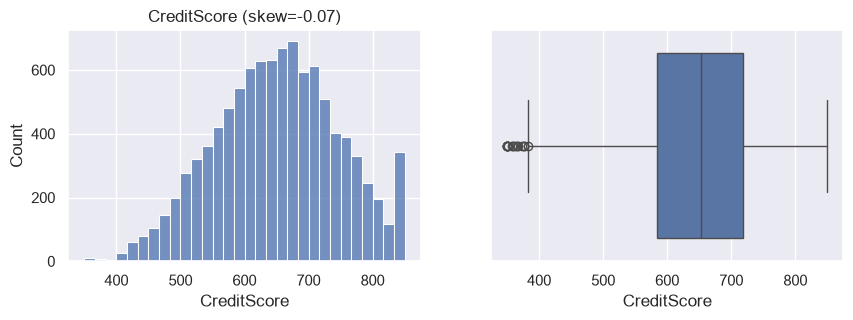

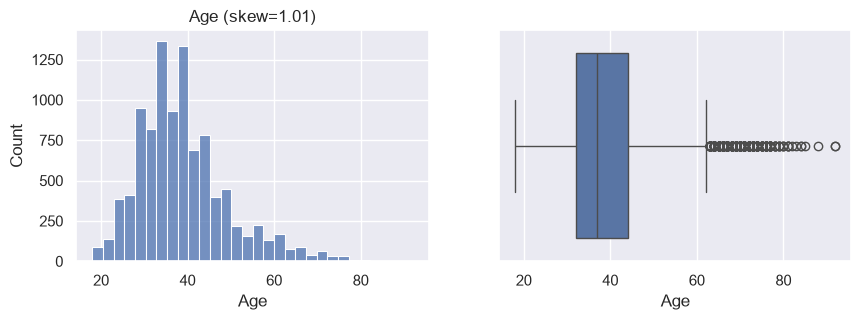

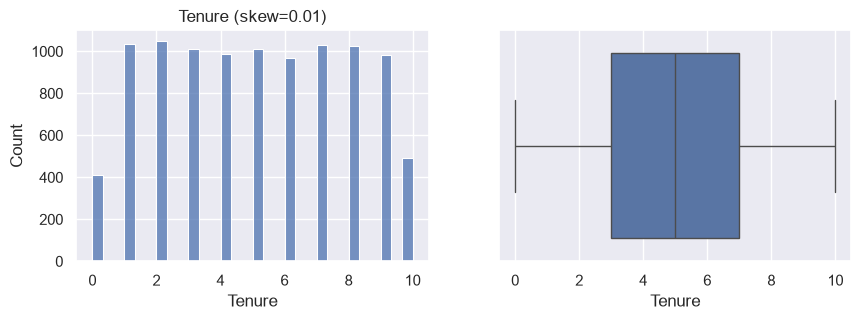

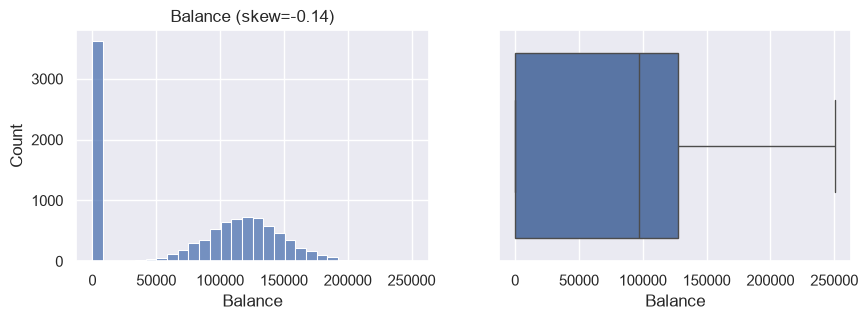

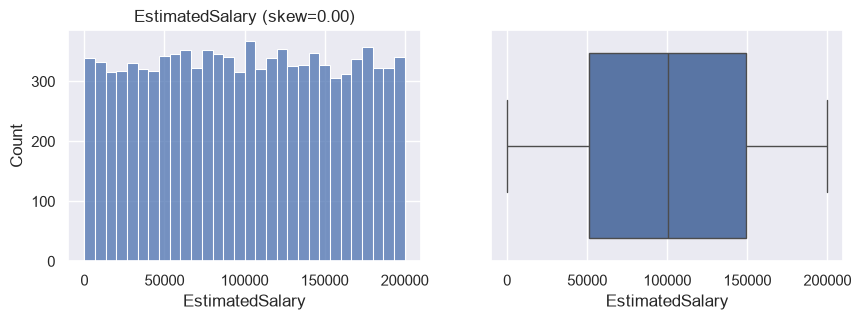

Geography
France     0.501
Germany    0.251
Spain      0.248
Name: proportion, dtype: float64 

Gender
Male      0.546
Female    0.454
Name: proportion, dtype: float64 

NumOfProducts
1    0.508
2    0.459
3    0.027
4    0.006
Name: proportion, dtype: float64 

HasCrCard
1    0.706
0    0.294
Name: proportion, dtype: float64 

IsActiveMember
1    0.515
0    0.485
Name: proportion, dtype: float64 



In [31]:
num = ['CreditScore','Age','Tenure','Balance','EstimatedSalary']
for c in num:
    fig, ax = plt.subplots(1, 2, figsize=(10,3))
    sns.histplot(df[c], bins=30, ax=ax[0]); sns.boxplot(x=df[c], ax=ax[1])
    ax[0].set_title(f'{c} (skew={df[c].skew():.2f})'); plt.show()
cat = ['Geography','Gender','NumOfProducts','HasCrCard','IsActiveMember']
for c in cat:
    print(df[c].value_counts(normalize=True).round(3), chr(10))

In [32]:
rows = []
for c in num:
    q1, q3 = df[c].quantile([.25, .75])
    iqr = q3 - q1
    outliers = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    rows.append({'column': c, 'min': df[c].min(), 'median': df[c].median(), 'max': df[c].max(),
                 'skew': round(df[c].skew(), 2), 'share_zero_%': round((df[c] == 0).mean()*100, 1),
                 'outliers_by_IQR': int(outliers)})
print(pd.DataFrame(rows).to_string(index=False))


         column    min     median       max  skew  share_zero_%  outliers_by_IQR
    CreditScore 350.00    652.000    850.00 -0.07           0.0               15
            Age  18.00     37.000     92.00  1.01           0.0              359
         Tenure   0.00      5.000     10.00  0.01           4.1                0
        Balance   0.00  97198.540 250898.09 -0.14          36.2                0
EstimatedSalary  11.58 100193.915 199992.48  0.00           0.0                0
